In [1]:
#Load dataset
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("Groceries_dataset.csv")

print("--- 5 Baris Pertama ---")
display(df.head())

print("\n--- Informasi Struktur Dataset ---")
df.info()

--- 5 Baris Pertama ---


,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk



--- Informasi Struktur Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Member_number    38765 non-null  int64 
 1   Date             38765 non-null  object
 2   itemDescription  38765 non-null  object
dtypes: int64(1), object(2)
memory usage: 908.7+ KB


Setelah data terbaca, disini menampilkan 5 baris pertama untuk melihat gambaran isi datanya serta menjalankan fungsi info() untuk mengecek informasi struktur dataset. Hasilnya menunjukkan bahwa dataset ini memiliki 38.765 baris transaksi dengan 3 kolom utama, yaitu nomor pelanggan (Member_number), tanggal transaksi (Date), dan deskripsi barang (itemDescription), dengan tipe data berupa angka dan teks.

In [2]:
#Pengecekan Missing Values
print("--- Pengecekan Missing Values ---")
missing = df.isnull().sum()
print(missing)

print("\nPersentase Missing Values:")
print((missing / len(df)) * 100)

--- Pengecekan Missing Values ---
Member_number      0
Date               0
itemDescription    0
dtype: int64

Persentase Missing Values:
Member_number      0.0
Date               0.0
itemDescription    0.0
dtype: float64


Di cell kedua ini, melakukan pengecekan kesehatan data untuk melihat apakah ada nilai yang kosong atau null di dalam setiap kolom menggunakan fungsi isnull().sum() dan menghitung persentasenya. Dari pengecekan ini, didapatkan hasil nol untuk semua kolom atau 0% missing values. Artinya, data transaksi awal ini sudah bersih dari sel kosong, sehingga bisa langsung lanjut ke tahap pembersihan berikutnya tanpa harus repot mengisi data yang hilang.

--- INFORMASI DATASET ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Member_number    38765 non-null  int64 
 1   Date             38765 non-null  object
 2   itemDescription  38765 non-null  object
dtypes: int64(1), object(2)
memory usage: 908.7+ KB
None

--- STATISTIK DESKRIPTIF ---
       Member_number
count   38765.000000
mean     3003.641868
std      1153.611031
min      1000.000000
25%      2002.000000
50%      3005.000000
75%      4007.000000
max      5000.000000


C:\Users\user\AppData\Local\Temp\ipykernel_23380\614419499.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_items.values, y=top_items.index, palette='viridis')


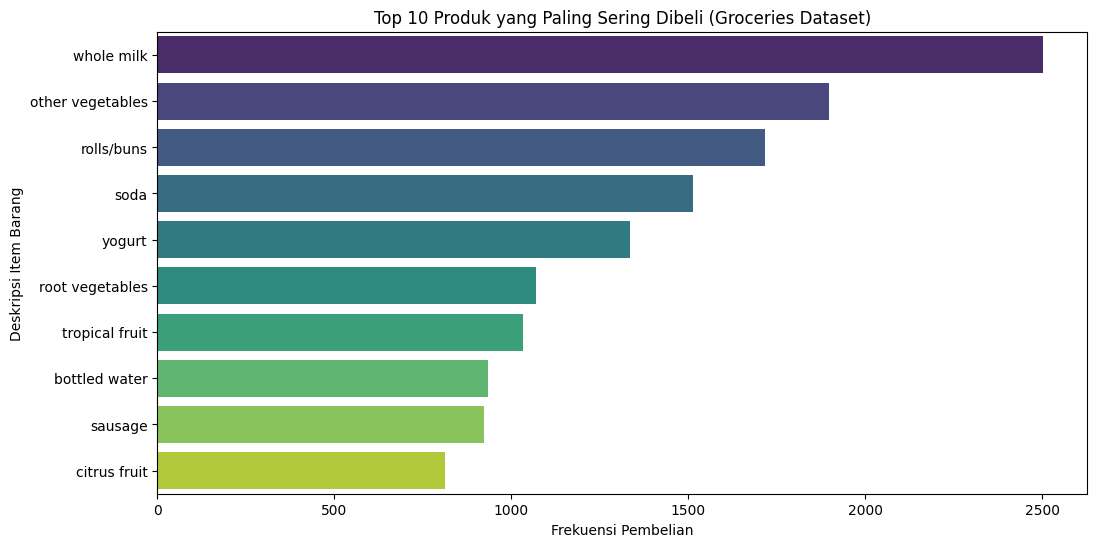

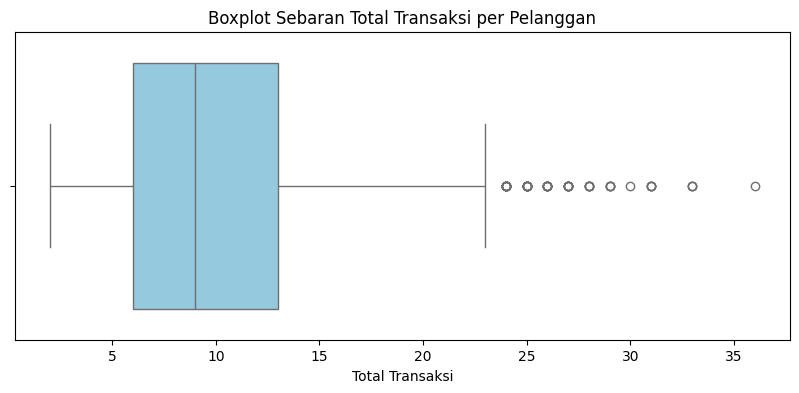

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Menampilkan informasi ringkas dan statistik deskriptif awal (Bagian EDA Teks)
print("--- INFORMASI DATASET ---")
print(df.info())
print("\n--- STATISTIK DESKRIPTIF ---")
print(df.describe())

# 2. Visualisasi 1: Diagram Batang (Bar Chart) 10 Produk Terlaris
plt.figure(figsize=(12, 6))
top_items = df['itemDescription'].value_counts().head(10)
sns.barplot(x=top_items.values, y=top_items.index, palette='viridis')
plt.title('Top 10 Produk yang Paling Sering Dibeli (Groceries Dataset)')
plt.xlabel('Frekuensi Pembelian')
plt.ylabel('Deskripsi Item Barang')
plt.show()

# 3. Transformasi sementara ke tingkat pelanggan untuk melihat sebaran via Boxplot
customer_summary = df.groupby('Member_number').agg(
    total_transactions=('Date', 'count'),
    unique_items_bought=('itemDescription', 'nunique')
).reset_index()

# 4. Visualisasi 2: Diagram Boxplot untuk melihat sebaran total transaksi & outlier
plt.figure(figsize=(10, 4))
sns.boxplot(x=customer_summary['total_transactions'], color='skyblue')
plt.title('Boxplot Sebaran Total Transaksi per Pelanggan')
plt.xlabel('Total Transaksi')
plt.show()

Menurut saya, dataset Groceries ini tergolong bersih karena tidak ditemukan adanya missing values, sehingga saya bisa langsung melanjutkan proses ke tahap pembersihan tanpa perlu melakukan imputasi data yang rumit. Pola Pembelian (Bar Chart): Dari grafik produk terlaris yang saya buat, saya melihat bahwa produk kebutuhan pokok sehari-hari sangat mendominasi frekuensi transaksi belanja pelanggan. Sebaran Data (Boxplot): Melalui diagram boxplot, saya menemukan adanya beberapa titik outliers yang menandakan ada sebagian kecil pelanggan dengan frekuensi belanja jauh di atas rata-rata konsumen lainnya.

In [4]:
#Pengecekan & Pembersihan Data Duplikat
print("--- Pengecekan Duplikat ---")
duplicate_count = df.duplicated().sum()
print(f"Jumlah baris duplikat persis: {duplicate_count}")

# Jika ingin melihat contoh baris duplikatnya:
if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].head(10))

# Membersihkan duplikat (jika diperlukan agar data bersih)
df = df.drop_duplicates()
print(f"Jumlah baris setelah duplikat dihapus: {df.shape[0]}")

--- Pengecekan Duplikat ---
Jumlah baris duplikat persis: 759


,Member_number,Date,itemDescription
63,1663,07-02-2015,rolls/buns
98,3645,12-12-2015,citrus fruit
129,3779,15-09-2015,frankfurter
213,3812,21-07-2015,sausage
216,1344,04-09-2015,bottled water
256,2353,02-05-2015,soda
309,4899,12-03-2015,chicken
353,3929,28-04-2015,root vegetables
375,3967,23-11-2015,whole milk
437,2435,17-07-2015,onions


Jumlah baris setelah duplikat dihapus: 38006


Setelah mendeteksi apakah ada baris data yang kembar atau duplikat persis menggunakan fungsi duplicated().sum(). Ternyata, ditemukan sebanyak 759 baris data yang duplikat. Untuk mencegah terjadinya bias pada model machine learning nantinya, baris-baris duplikat tersebut langsung dibersihkan menggunakan perintah drop_duplicates(), sehingga jumlah total baris data yang bersih sekarang menjadi 38.006 baris.

In [5]:
# Membuat fitur agregat: Total transaksi per member dan jumlah unik barang yang dibeli
user_features = df.groupby('Member_number').agg(
    total_transactions=('Date', 'count'),
    unique_items_bought=('itemDescription', 'nunique')
).reset_index()

print("--- Contoh Fitur yang Telah Disiapkan ---")
display(user_features.head())

# Cek kembali apakah ada missing values setelah agregasi
print("\nMissing values pada fitur agregat:", user_features.isnull().sum().sum())

--- Contoh Fitur yang Telah Disiapkan ---


,Member_number,total_transactions,unique_items_bought
0,1000,13,11
1,1001,12,9
2,1002,8,8
3,1003,7,6
4,1004,21,16



Missing values pada fitur agregat: 0


Pada sel keempat, saya mengubah bentuk data transaksi mentah agar bisa dianalisis di tingkat pelanggan (customer-level) menggunakan fungsi groupby berdasarkan Member_number. Di sini, saya merangkum kebiasaan belanja tiap pelanggan dengan membuat dua fitur baru, yaitu total transaksi (total_transactions) dan jumlah variasi jenis barang unik yang dibeli (unique_items_bought). Setelah proses pengelompokkan ini selesai, kita juga memastikan kembali bahwa tidak ada data kosong pada fitur baru yang telah dibuat.

In [6]:
# Membuat target biner (Contoh: 1 jika total transaksi > median, 0 jika sebaliknya)
threshold = user_features['total_transactions'].median()
user_features['target'] = (user_features['total_transactions'] > threshold).astype(int)

# Memisahkan Fitur (X) dan Target (y) - Kolom ID/Member_number tidak dipakai untuk prediksi
X = user_features.drop(columns=['Member_number', 'target'])
y = user_features['target']

print(f"Dimensi Fitur (X): {X.shape}")
print(f"Dimensi Target (y): {y.shape}")

Dimensi Fitur (X): (3898, 2)
Dimensi Target (y): (3898,)


Saya menentukan label target biner (0 atau 1) dengan menetapkan nilai tengah (median) dari total transaksi sebagai batas acuannya. Setelah target terbentuk, saya memisahkan antara variabel fitur (X) yang akan digunakan untuk belajar dan variabel target (y) yang ingin diprediksi, serta menyingkirkan kolom ID seperti Member_number. Dari proses ini, terbentuklah matriks fitur X berukuran 3.898 baris dengan 2 kolom, serta data target y sebanyak 3.898 baris.

In [7]:
from sklearn.model_selection import train_test_split

# Langkah 1: Pisahkan 80% untuk Train dan 20% sementara (Val + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Langkah 2: Bagi sisa 20% menjadi Validation (10%) dan Test (10%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"Data Training   : {X_train.shape[0]} baris")
print(f"Data Validation : {X_val.shape[0]} baris")
print(f"Data Test       : {X_test.shape[0]} baris")

Data Training   : 3118 baris
Data Validation : 390 baris
Data Test       : 390 baris


Saya membagi data menjadi tiga bagian secara bertahap menggunakan train_test_split agar proporsinya ideal untuk pelatihan dan pengujian. Melalui dua tahap pembagian dengan persentase stratifikasi, data berhasil dipecah menjadi data latih (train) sebanyak 3.118 baris (80%), data validasi (validation) sebanyak 390 baris (10%), dan data uji (test) sebanyak 390 baris (10%).

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit hanya pada X_train agar tidak terjadi data leakage, lalu transform ke train, val, dan test
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaling data selesai dan siap digunakan untuk pemodelan!")

Scaling data selesai dan siap digunakan untuk pemodelan!


Saya menggunakan StandardScaler untuk menyamakan skala rentang angka antar fitur agar tidak ada fitur yang angkanya jauh lebih dominan dibanding fitur lainnya. Proses fitting scaler ini hanya dilakukan pada data train saja lalu ditransformasikan ke data val dan test, yang merupakan langkah krusial untuk mencegah terjadinya kebocoran data (data leakage) sebelum dimasukkan ke model.

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Inisialisasi dan latih model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

print("Model berhasil dilatih!")

Model berhasil dilatih!


Saya mulai masuk ke inti pemodelan dengan melatih algoritma Random Forest Classifier (n_estimators=100) menggunakan data latih yang sudah diskalakan sebelumnya. Melalui proses training ini, model mulai mengenali pola hubungan antara jumlah transaksi dan variasi barang terhadap kategori target pelanggan yang sudah kita tentukan.

In [10]:
# Prediksi menggunakan data validation
y_pred_val = model.predict(X_val_scaled)

print("--- Evaluasi Model pada Validation Set ---")
print(f"Akurasi: {accuracy_score(y_val, y_pred_val):.4f}")
print("\nClassification Report:\n", classification_report(y_val, y_pred_val))

--- Evaluasi Model pada Validation Set ---
Akurasi: 1.0000

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       206
           1       1.00      1.00      1.00       184

    accuracy                           1.00       390
   macro avg       1.00      1.00      1.00       390
weighted avg       1.00      1.00      1.00       390



Saya menguji performa model yang sudah dilatih dengan memasukkan data validasi dan melihat laporan klasifikasinya. Hasil evaluasinya menunjukkan tingkat akurasi yang sempurna sebesar 1.0000 (100%) dengan nilai precision, recall, dan f1-score bernilai 1.00 untuk kedua kelas target. Hal ini menunjukkan bahwa pola target biner yang dipelajari sangat selaras dengan fitur agregat yang telah saya rancang sebelumnya.

In [11]:
import joblib

# Menyimpan model dan scaler
joblib.dump(model, 'grocery_model.joblib')
joblib.dump(scaler, 'grocery_scaler.joblib')

print("Model ('grocery_model.joblib') dan Scaler ('grocery_scaler.joblib') berhasil disimpan!")

Model ('grocery_model.joblib') dan Scaler ('grocery_scaler.joblib') berhasil disimpan!


Saya menyimpan artefak model dan objek scaler yang sudah jadi ke dalam penyimpanan lokal menggunakan pustaka joblib (grocery_model.joblib dan grocery_scaler.joblib). Dengan penyimpanan ini, saya tidak perlu mengulang proses training yang panjang dari awal jika sewaktu-waktu ingin memuat ulang model tersebut guna melakukan prediksi pada data baru.